# Forecasting Daily Traffic Incidents on Pasig City's Major Roads

**IT 201 – Platform Technologies · Final Case Study · Regression notebook**

> **DRAFT STARTER – the group must review every step, adjust it, and rewrite the explanations in its own words.**

## 1. Background of the Study

**Title of the study:** Forecasting Daily Traffic Incidents on Pasig City's Major Roads (C5, Ortigas Avenue, Marcos Highway)

**Source of data:** MMDA traffic alerts posted on Twitter/X by @MMDA, as compiled in the file `data_mmda_traffic_spatial.csv`.
*TODO (group): add the exact download link / author of the CSV, the download date, and the citation.*

**Raw dataset:** 17,312 rows × 13 columns covering Metro Manila (20 Aug 2018 – 27 Dec 2020). Only the 1,723 rows where `City == "Pasig City"` are used. After cleaning and reshaping, the **prepared dataset has 1,656 rows × 8 columns** (552 days × 3 major roads).

| Column | Meaning |
|---|---|
| Date, Time | When the alert was posted / incident reported |
| City | City where MMDA placed the incident |
| Location | Road segment or landmark named in the alert |
| Latitude, Longitude | Geocoded coordinates of the location (about 100 distinct pairs for Pasig, so location-level, not exact GPS) |
| High_Accuracy | 1 if the geocoding is precise, 0 otherwise |
| Direction | NB / SB / EB / WB |
| Type | Incident type (vehicular accident, stalled vehicle, multiple collision, ...) |
| Lanes_Blocked | Number of lanes occupied |
| Involved | Vehicles involved |
| Tweet, Source | Alert text and URL of the tweet |

**Unit of analysis (after preparation):** one row per **major road per day** (C5, Ortigas, Marcos Highway).

**Selected features (independent variables):** major road, day of week, month, the major road's incident count 7 days earlier (`Incidents_Lag7`), and its average over the previous 7 days (`Incidents_Roll7`).

**Target (dependent variable):** `Incidents` – number of MMDA-reported incidents on that major road that day.

**Objective:** use regression to predict how many incidents to expect on each major road each day, so that the MMDA and Pasig City's traffic management office can plan where to place enforcers and tow trucks.

**Important limitations (see the conclusion):** the data holds only incidents that MMDA tweeted, not all incidents; March 2020 onward (COVID-19 lockdown) is excluded from modeling because activity collapses.

## 2. Data Collection / Loading

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart styling (categorical hues in a fixed order; muted ink for text)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, MUTED, GRID, GREY = '#0b0b0b', '#52514e', '#e4e3df', '#b9b8b2'
ROAD_COLORS = {'C5': BLUE, 'ORTIGAS': ORANGE, 'MARCOS': AQUA}
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.labelcolor': MUTED,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'legend.frameon': False,
})

RAW_PATH = 'data_mmda_traffic_spatial.csv'
raw = pd.read_csv(RAW_PATH)
print('Raw dataset dimensions:', raw.shape)
raw.head()

Raw dataset dimensions: (17312, 13)


,Date,Time,City,Location,Latitude,Longitude,High_Accuracy,Direction,Type,Lanes_Blocked,Involved,Tweet,Source
0,2018-08-20,7:55 AM,Pasig City,ORTIGAS EMERALD,14.586343,121.061481,1,EB,VEHICULAR ACCIDENT,1.0,TAXI AND MC,MMDA ALERT: Vehicular accident at Ortigas Emer...,https://twitter.com/mmda/status/10313302019705...
1,2018-08-20,8:42 AM,Mandaluyong,EDSA GUADIX,14.589432,121.057243,1,NB,STALLED L300 DUE TO MECHANICAL PROBLEM,1.0,L300,MMDA ALERT: Stalled L300 due to mechanical pro...,https://twitter.com/mmda/status/10313462477459...
2,2018-08-20,9:13 AM,Makati City,EDSA ROCKWELL,14.559818,121.040737,1,SB,VEHICULAR ACCIDENT,1.0,SUV AND L300,MMDA ALERT: Vehicular accident at EDSA Rockwel...,https://twitter.com/mmda/status/10313589669896...
3,2018-08-20,8:42 AM,Mandaluyong,EDSA GUADIX,14.589432,121.057243,1,NB,STALLED L300 DUE TO MECHANICAL PROBLEM,1.0,L300,MMDA ALERT: Stalled L300 due to mechanical pro...,https://twitter.com/mmda/status/10313590696535...
4,2018-08-20,10:27 AM,San Juan,ORTIGAS CLUB FILIPINO,14.601846,121.046754,1,EB,VEHICULAR ACCIDENT,1.0,2 CARS,MMDA ALERT: Vehicular accident at Ortigas Club...,https://twitter.com/mmda/status/10313711248424...


## 3. Data Information and Summary Statistics

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 17312 entries, 0 to 17311
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           17312 non-null  str    
 1   Time           17190 non-null  str    
 2   City           17125 non-null  str    
 3   Location       17289 non-null  str    
 4   Latitude       17312 non-null  float64
 5   Longitude      17312 non-null  float64
 6   High_Accuracy  17312 non-null  int64  
 7   Direction      16455 non-null  str    
 8   Type           17255 non-null  str    
 9   Lanes_Blocked  16625 non-null  float64
 10  Involved       16880 non-null  str    
 11  Tweet          17312 non-null  str    
 12  Source         17312 non-null  str    
dtypes: float64(3), int64(1), str(9)
memory usage: 1.7 MB


In [3]:
print('First 5 rows'); display(raw.head())
print('Last 5 rows');  display(raw.tail())

First 5 rows


,Date,Time,City,Location,Latitude,Longitude,High_Accuracy,Direction,Type,Lanes_Blocked,Involved,Tweet,Source
0,2018-08-20,7:55 AM,Pasig City,ORTIGAS EMERALD,14.586343,121.061481,1,EB,VEHICULAR ACCIDENT,1.0,TAXI AND MC,MMDA ALERT: Vehicular accident at Ortigas Emer...,https://twitter.com/mmda/status/10313302019705...
1,2018-08-20,8:42 AM,Mandaluyong,EDSA GUADIX,14.589432,121.057243,1,NB,STALLED L300 DUE TO MECHANICAL PROBLEM,1.0,L300,MMDA ALERT: Stalled L300 due to mechanical pro...,https://twitter.com/mmda/status/10313462477459...
2,2018-08-20,9:13 AM,Makati City,EDSA ROCKWELL,14.559818,121.040737,1,SB,VEHICULAR ACCIDENT,1.0,SUV AND L300,MMDA ALERT: Vehicular accident at EDSA Rockwel...,https://twitter.com/mmda/status/10313589669896...
3,2018-08-20,8:42 AM,Mandaluyong,EDSA GUADIX,14.589432,121.057243,1,NB,STALLED L300 DUE TO MECHANICAL PROBLEM,1.0,L300,MMDA ALERT: Stalled L300 due to mechanical pro...,https://twitter.com/mmda/status/10313590696535...
4,2018-08-20,10:27 AM,San Juan,ORTIGAS CLUB FILIPINO,14.601846,121.046754,1,EB,VEHICULAR ACCIDENT,1.0,2 CARS,MMDA ALERT: Vehicular accident at Ortigas Club...,https://twitter.com/mmda/status/10313711248424...


Last 5 rows


,Date,Time,City,Location,Latitude,Longitude,High_Accuracy,Direction,Type,Lanes_Blocked,Involved,Tweet,Source
17307,2020-12-27,12:59 PM,Manila,QUIRINO GUAZON PETRON,14.585503,120.993783,1,SB,VEHICULAR ACCIDENT,1.0,MOTORCYCLE,MMDA ALERT: VEHICULAR ACCIDENT AT QUIRINO GUAZ...,https://twitter.com/mmda/status/13430604432589...
17308,2020-12-27,3:08 PM,Makati City,EDSA ESTRELLA,14.559818,121.040737,1,NB,STALLED VAN DUE TO TIRE PROBLEM,1.0,VAN,MMDA ALERT: STALLED VAN DUE TO TIRE PROBLEM AT...,https://twitter.com/mmda/status/13430967348098...
17309,2020-12-27,3:23 PM,Quezon City,EDSA P TUAZON FLYOVER,14.616404,121.052548,1,SB,VEHICULAR ACCIDENT,1.0,CAR AND MOTORCYCLE,MMDA ALERT: VEHICULAR ACCIDENT AT EDSA P. TUAZ...,https://twitter.com/mmda/status/13430968412152...
17310,2020-12-27,7:46 PM,Quezon City,ORTIGAS AVE EDSA POEA,14.593548,121.058028,1,WB,STALLED MULTICAB DUE TO MECHANICAL PROBLEM,1.0,MULTICAB,MMDA ALERT: STALLED MULTICAB DUE TO MECHANICAL...,https://twitter.com/mmda/status/13431795574073...
17311,2020-12-27,9:39 PM,Manila,LEGARDA STA CATALINA COLLEGE,14.600902,120.997352,1,WB,VEHICULAR ACCIDENT,1.0,MOTORCYCLE,MMDA ALERT: VEHICULAR ACCIDENT AT LEGARDA STA....,https://twitter.com/mmda/status/13431936109723...


In [4]:
print('Missing values per column (whole file):')
print(raw.isnull().sum())
print()
print('Records per city (top 8):')
print(raw['City'].value_counts(dropna=False).head(8))
print()
print('Date range:', raw['Date'].min(), '->', raw['Date'].max())
print('Duplicate rows (all columns):', raw.duplicated().sum())

Missing values per column (whole file):
Date               0
Time             122
City             187
Location          23
Latitude           0
Longitude          0
High_Accuracy      0
Direction        857
Type              57
Lanes_Blocked    687
Involved         432
Tweet              0
Source             0
dtype: int64

Records per city (top 8):
City
Quezon City    8725
Mandaluyong    2978
Makati City    2431
Pasig City     1723
Pasay City      445
Manila          354
NaN             187
San Juan        121
Name: count, dtype: int64

Date range: 2018-08-20 -> 2020-12-27
Duplicate rows (all columns): 0


In [5]:
pasig_raw = raw[raw['City'] == 'Pasig City']
print('Pasig City rows:', pasig_raw.shape[0])
print()
print('Missing values in the Pasig rows:')
print(pasig_raw.isnull().sum()[lambda s: s > 0])
print()
print('Distinct Location spellings:', pasig_raw['Location'].nunique(), '| distinct Type labels:', pasig_raw['Type'].nunique())
print('Lanes_Blocked values:', pasig_raw['Lanes_Blocked'].value_counts(dropna=False).to_dict())
print('High_Accuracy values:', pasig_raw['High_Accuracy'].value_counts().to_dict())

Pasig City rows: 1723

Missing values in the Pasig rows:
Time              8
Direction        46
Type              5
Lanes_Blocked    49
Involved         40
dtype: int64

Distinct Location spellings: 242 | distinct Type labels: 111
Lanes_Blocked values: {1.0: 1543, 2.0: 130, nan: 49, 6.0: 1}
High_Accuracy values: {1: 1675, 0: 48}


**Observations (draft):**
- The raw file covers all of Metro Manila; Pasig City is one of several cities.
- Some columns have missing values (`Time`, `Direction`, `Type`, `Lanes_Blocked`, `Involved`, `City`). The model only needs the date, the major road, and the counts, so these gaps matter mostly for the exploratory charts.
- There are many different spellings of locations and incident types, so they must be grouped before analysis.

## 4. Data Cleaning

Each step below states **what** was done and **why**.

In [6]:
# 4.1 Keep Pasig City records only
pasig = raw[raw['City'] == 'Pasig City'].copy()
print(f'4.1 Pasig filter: {len(raw):,} -> {len(pasig):,} rows')

# 4.2 Convert the date (the original uses ISO format YYYY-MM-DD)
pasig['Date'] = pd.to_datetime(pasig['Date'], format='%Y-%m-%d')
print('4.2 Date range:', pasig['Date'].min().date(), '->', pasig['Date'].max().date())

4.1 Pasig filter: 17,312 -> 1,723 rows
4.2 Date range: 2018-08-20 -> 2020-12-26


In [7]:
# 4.3 Hour of the incident. Parse the Time column; where it is missing or malformed
#     (e.g. '9:00PM', '8:26M', '10:06'), recover the time from the alert text ("... as of 7:55 AM").
TIME_RE = re.compile(r'(\d{1,2})\s*:\s*(\d{2})\s*\.?\s*([AaPp])\.?\s*[Mm]?')

def to_hour(text):
    m = TIME_RE.search(str(text))
    if not m:
        return np.nan
    h = int(m.group(1))
    if not 1 <= h <= 12:
        return np.nan
    return h % 12 + (12 if m.group(3).upper() == 'P' else 0)

hour_from_time = pasig['Time'].apply(to_hour)
hour_from_tweet = pasig['Tweet'].apply(to_hour)
pasig['Hour'] = hour_from_time.fillna(hour_from_tweet)
print('4.3 Time column unusable in', hour_from_time.isna().sum(), 'rows;',
      'recovered from the tweet text in', (hour_from_time.isna() & hour_from_tweet.notna()).sum(), 'rows;',
      'still missing:', pasig['Hour'].isna().sum())

4.3 Time column unusable in 10 rows; recovered from the tweet text in 3 rows; still missing: 7


In [8]:
# 4.4 Remove duplicate records. The same incident is sometimes tweeted twice.
n0 = len(pasig)
pasig = pasig.drop_duplicates(subset='Source')
n1 = len(pasig)
key = ['Date', 'Time', 'Location', 'Direction', 'Type']
pasig = pasig.drop_duplicates(subset=key)
n2 = len(pasig)
print(f'4.4 Duplicate tweets removed (same URL): {n0 - n1}')
print(f'    Same incident tweeted twice (same date, time, location, direction, type): {n1 - n2}')
print(f'    Rows after de-duplication: {n2:,}')

4.4 Duplicate tweets removed (same URL): 3
    Same incident tweeted twice (same date, time, location, direction, type): 35
    Rows after de-duplication: 1,685


In [9]:
# 4.5 Group the 242 location spellings into the major major roads.
loc = pasig['Location'].str.upper().str.strip()
pasig['MajorRoad'] = np.select(
    [loc.str.match(r'^C-?5'), loc.str.startswith('MARCOS'), loc.str.startswith('ORTIGAS')],
    ['C5', 'MARCOS', 'ORTIGAS'], default='OTHER')
print(pasig['MajorRoad'].value_counts())
print()
print('Examples of rows left out as OTHER (EDSA, Meralco Onyx, ADB, Poveda, ...):')
print(loc[pasig['MajorRoad'] == 'OTHER'].value_counts().head(8).to_dict())

MajorRoad
C5         1025
ORTIGAS     326
MARCOS      260
OTHER        74
Name: count, dtype: int64

Examples of rows left out as OTHER (EDSA, Meralco Onyx, ADB, Poveda, ...):
{'MERALCO ONYX': 11, 'FVR ROAD CAMP ATIENZA': 4, 'EDSA PIONEER GO HOTEL': 2, 'ADB POVEDA': 2, 'EDSA BONI AMBERS': 2, 'EDSA GO HOTEL PIONEER': 2, 'COMMONWEALTH ZUZUARREGUI': 1, 'COMMONWEALTH TANDANG SORA': 1}


In [10]:
# 4.6 Keep the three major roads. (Rows with a missing City, e.g. many on Marcos Highway, cannot be
#     assigned to Pasig and are not used; see the limitations.)
inc = pasig[pasig['MajorRoad'] != 'OTHER'].copy()
print('Clean incident table:', inc.shape)
print('Missing values left (used only for EDA):')
print(inc[['Hour', 'Direction', 'Type', 'Lanes_Blocked', 'Involved']].isnull().sum().to_dict())

Clean incident table: (1611, 15)
Missing values left (used only for EDA):
{'Hour': 7, 'Direction': 37, 'Type': 5, 'Lanes_Blocked': 42, 'Involved': 39}


**What was done and why (draft – group to confirm and rewrite):**
1. Filtered to `City == "Pasig City"` (17,312 → 1,723 rows) so the study is about Pasig.
2. Converted the date to a proper date type.
3. Fixed or recovered incident hours: the `Time` column was unusable in 10 rows (8 missing, 2 malformed such as `8:26M` and `10:06`); 3 were recovered from the alert text and 7 stay missing. Hours only feed one exploratory chart, so these rows were kept.
4. Removed 38 duplicates (3 repeated tweets with the same URL, and 35 cases of the same incident tweeted twice) so incidents are not double-counted: 1,723 → 1,685 rows.
5. Grouped the 242 location spellings into three major roads: C5 (1,025 rows), Ortigas (326) and Marcos Highway (260). The remaining 74 rows (EDSA, Meralco Onyx, ADB, Poveda, etc.) are too scattered to model and were excluded, leaving **1,611 incidents**.
6. Missing `Direction`, `Type`, `Lanes_Blocked` and `Involved` do not affect the daily-count target, so they were not imputed.

## 5. Data Engineering

**Why aggregate:** the original rows are individual incidents. To predict *how many* incidents to expect, the data is reshaped to **one row per major road per day**, and days with no incident are added explicitly as zeros (the original file only lists days with at least one incident).

**Why stop at 29 Feb 2020:** activity collapses in March 2020 (COVID-19 lockdown), so those months are not comparable with normal traffic.

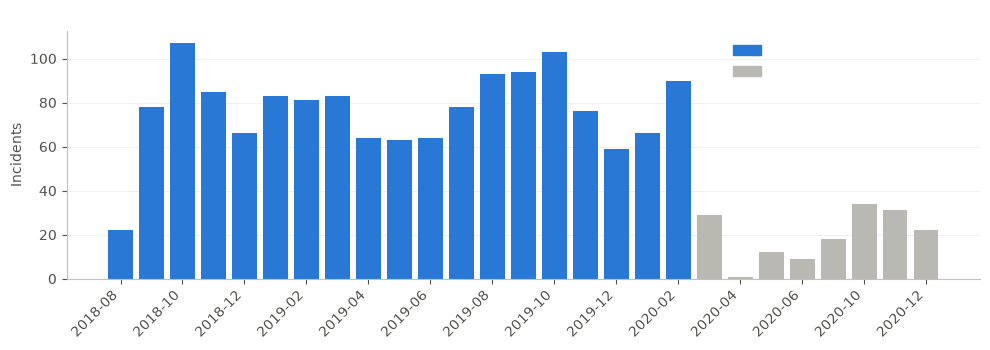

In [11]:
monthly = inc.groupby(inc['Date'].dt.to_period('M')).size()
CUTOFF = pd.Timestamp('2020-02-29')
used = [p.to_timestamp() <= CUTOFF for p in monthly.index]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(range(len(monthly)), monthly.values, color=[BLUE if u else GREY for u in used],
       width=0.8)
ax.set_xticks(range(0, len(monthly), 2))
ax.set_xticklabels([str(p) for p in monthly.index[::2]], rotation=45, ha='right')
ax.set_title('Reported incidents per month (three major roads)')
ax.set_ylabel('Incidents')
ax.legend(handles=[Patch(color=BLUE, label='Used for modeling'), Patch(color=GREY, label='Excluded (lockdown period)')],
          loc='upper right')
plt.tight_layout(); plt.show()

In [12]:
# 5.1 Build the road-day table (with explicit zero-incident days)
START = inc['Date'].min().normalize()
major_roads = ['C5', 'ORTIGAS', 'MARCOS']
model_inc = inc[inc['Date'] <= CUTOFF]
days = pd.date_range(START, CUTOFF)

counts = model_inc.groupby(['Date', 'MajorRoad']).size()
grid = (counts.reindex(pd.MultiIndex.from_product([days, major_roads], names=['Date', 'MajorRoad']), fill_value=0)
        .rename('Incidents').reset_index()
        .sort_values(['MajorRoad', 'Date']).reset_index(drop=True))
print('Road-day grid:', grid.shape, '| days:', len(days), '| major roads:', len(major_roads))

# 5.2 Derived variables (each has a clear purpose)
grid['DayOfWeek'] = grid['Date'].dt.dayofweek          # 0 = Monday ... 6 = Sunday
grid['Month'] = grid['Date'].dt.month
grid['IsWeekend'] = (grid['DayOfWeek'] >= 5).astype(int)
g = grid.groupby('MajorRoad')['Incidents']
grid['Incidents_Lag7'] = g.shift(7)                                            # same weekday last week
grid['Incidents_Roll7'] = g.transform(lambda s: s.shift(1).rolling(7).mean())  # average of the previous 7 days (excludes today)

# 5.3 The first 7 days have no history, so they are dropped
eng = (grid.dropna().sort_values(['Date', 'MajorRoad']).reset_index(drop=True)
       [['Date', 'MajorRoad', 'DayOfWeek', 'Month', 'IsWeekend', 'Incidents_Lag7', 'Incidents_Roll7', 'Incidents']])
eng['Incidents_Lag7'] = eng['Incidents_Lag7'].astype(int)
print('Engineered dataset:', eng.shape, '| missing values:', int(eng.isnull().sum().sum()))

Road-day grid: (1677, 3) | days: 559 | major roads: 3
Engineered dataset: (1656, 8) | missing values: 0


In [13]:
# 5.4 Outlier check on the target
print(eng['Incidents'].describe())
print()
print('Highest road-days:')
print(eng.nlargest(5, 'Incidents')[['Date', 'MajorRoad', 'Incidents']].to_string(index=False))

count    1656.000000
mean        0.871981
std         1.169827
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         7.000000
Name: Incidents, dtype: float64

Highest road-days:
      Date MajorRoad  Incidents
2019-01-16        C5          7
2019-02-19        C5          7
2018-09-29        C5          6
2018-10-12        C5          6
2018-10-16        C5          6


In [14]:
# 5.5 Save the engineered dataset (deliverable)
eng.to_csv('engineered_pasig_major_road_day.csv', index=False)
print('Saved engineered_pasig_major_road_day.csv with dimensions', eng.shape)

Saved engineered_pasig_major_road_day.csv with dimensions (1656, 8)


**Pre-processing decisions (draft):**
- **Outliers:** the largest counts are plausible busy days, not errors, so they were **kept**.
- **Encoding and scaling:** major road, day of week and month are one-hot encoded and the two lag features are standardized **inside the model pipeline** (Section 8). They are fitted on the training data only, so no information from the test period leaks into training.
- **Derived variables:** `IsWeekend` is saved for reference but not used as a model feature (it duplicates `DayOfWeek`). The two lag features are the only history-based features.

## 6. Data Visualization (Exploratory Data Analysis)

In [15]:
print('First 5 rows'); display(eng.head())
print('Last 5 rows');  display(eng.tail())
print('Descriptive statistics'); display(eng.describe().T)

First 5 rows


,Date,MajorRoad,DayOfWeek,Month,IsWeekend,Incidents_Lag7,Incidents_Roll7,Incidents
0,2018-08-27,C5,0,8,0,2,0.857143,0
1,2018-08-27,MARCOS,0,8,0,0,0.285714,1
2,2018-08-27,ORTIGAS,0,8,0,1,0.428571,1
3,2018-08-28,C5,1,8,0,0,0.571429,3
4,2018-08-28,MARCOS,1,8,0,1,0.428571,0


Last 5 rows


,Date,MajorRoad,DayOfWeek,Month,IsWeekend,Incidents_Lag7,Incidents_Roll7,Incidents
1651,2020-02-28,MARCOS,4,2,0,0,0.142857,1
1652,2020-02-28,ORTIGAS,4,2,0,0,0.000000,2
1653,2020-02-29,C5,5,2,1,0,1.857143,2
1654,2020-02-29,MARCOS,5,2,1,0,0.285714,1
1655,2020-02-29,ORTIGAS,5,2,1,0,0.285714,1


Descriptive statistics


,count,mean,min,25%,50%,75%,max,std
Date,1656,2019-05-29 12:00:00,2018-08-27 00:00:00,2019-01-11 18:00:00,2019-05-29 12:00:00,2019-10-14 06:00:00,2020-02-29 00:00:00,NaN
DayOfWeek,1656.0,2.994565,0.0,1.0,3.0,5.0,6.0,1.99833
Month,1656.0,6.871377,1.0,3.0,8.0,10.0,12.0,3.787051
IsWeekend,1656.0,0.28442,0.0,0.0,0.0,1.0,1.0,0.451274
Incidents_Lag7,1656.0,0.865942,0.0,0.0,0.0,1.0,7.0,1.166563
Incidents_Roll7,1656.0,0.866287,0.0,0.428571,0.571429,1.142857,3.428571,0.702222
Incidents,1656.0,0.871981,0.0,0.0,0.0,1.0,7.0,1.169827


In [16]:
print('Distribution of the target (road-days by number of incidents):')
dist = eng['Incidents'].clip(upper=4).value_counts().sort_index()
dist.index = [str(i) if i < 4 else '4+' for i in dist.index]
print(dist.to_string())
print()
print('Road-days per major road:'); print(eng['MajorRoad'].value_counts().to_string())

Distribution of the target (road-days by number of incidents):
0     843
1     436
2     229
3      78
4+     70

Road-days per major road:
MajorRoad
C5         552
MARCOS     552
ORTIGAS    552


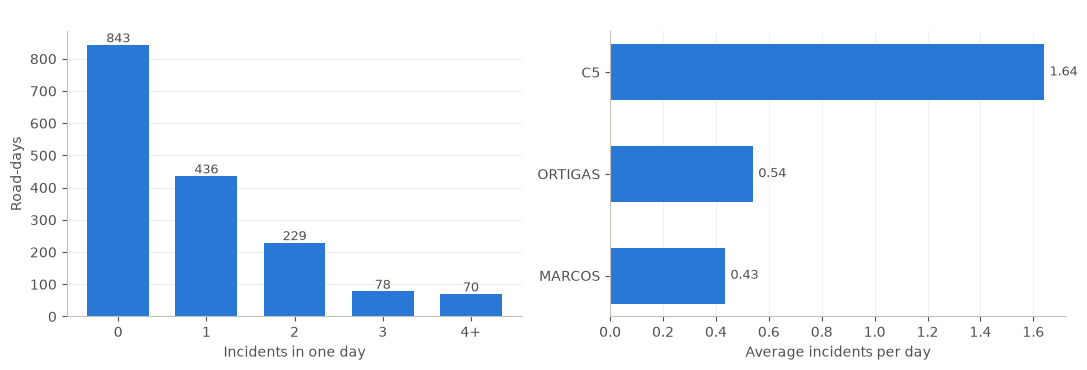

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# (a) target distribution
ax = axes[0]
ax.bar(dist.index, dist.values, color=BLUE, width=0.7)
for i, v in enumerate(dist.values):
    ax.text(i, v + 8, f'{v:,}', ha='center', color=MUTED, fontsize=9)
ax.set_title('How many incidents on a road-day?')
ax.set_xlabel('Incidents in one day'); ax.set_ylabel('Road-days')

# (b) average incidents by major road
ax = axes[1]
m = eng.groupby('MajorRoad')['Incidents'].mean().sort_values()
ax.barh(m.index, m.values, color=BLUE, height=0.55)
for i, v in enumerate(m.values):
    ax.text(v + 0.02, i, f'{v:.2f}', va='center', color=MUTED, fontsize=9)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title('Average incidents per day, by major road')
ax.set_xlabel('Average incidents per day')
plt.tight_layout(); plt.show()

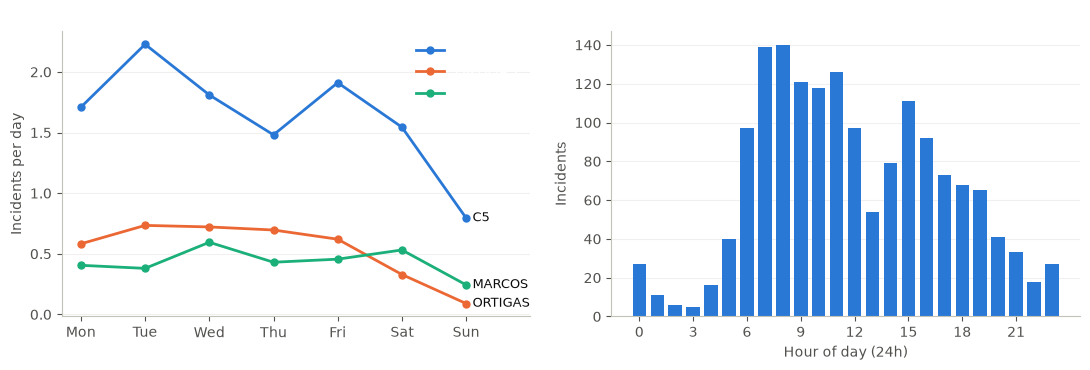

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# (c) day-of-week pattern per major road
ax = axes[0]
dow = eng.groupby(['DayOfWeek', 'MajorRoad'])['Incidents'].mean().unstack()
labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
for c in major_roads:
    ax.plot(labels, dow[c].values, color=ROAD_COLORS[c], lw=2, marker='o', ms=5, label=c)
    ax.text(6.1, dow[c].values[-1], c, color=INK, va='center', fontsize=9)
ax.set_xlim(-0.3, 7.0)
ax.set_title('Average incidents by day of week'); ax.set_ylabel('Incidents per day')
ax.legend(loc='upper right')

# (d) hour-of-day pattern
ax = axes[1]
hours = inc['Hour'].dropna().astype(int).value_counts().reindex(range(24), fill_value=0)
ax.bar(hours.index, hours.values, color=BLUE, width=0.75)
ax.set_title('Incidents by hour of day (all three major roads)')
ax.set_xlabel('Hour of day (24h)'); ax.set_ylabel('Incidents')
ax.set_xticks(range(0, 24, 3))
plt.tight_layout(); plt.show()

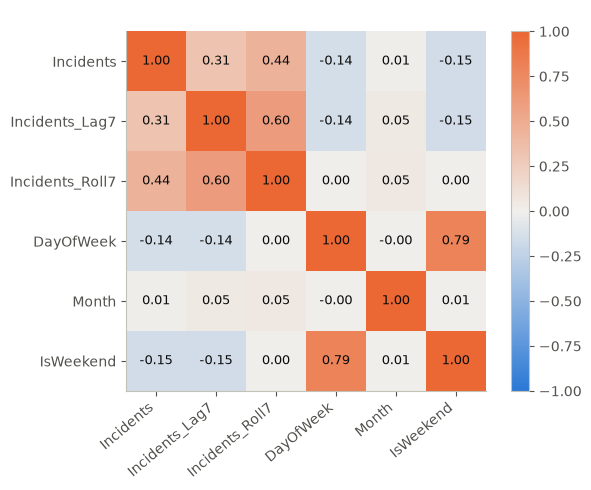

In [19]:
# Correlation heatmap (numeric view of the features and the target)
num = eng[['Incidents', 'Incidents_Lag7', 'Incidents_Roll7', 'DayOfWeek', 'Month', 'IsWeekend']]
corr = num.corr()
cmap = LinearSegmentedColormap.from_list('div', [BLUE, '#f0efec', ORANGE])
fig, ax = plt.subplots(figsize=(6.4, 5))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=40, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', color=INK, fontsize=9)
ax.set_title('Correlation between features and target')
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

**Findings (draft – confirm against the charts and put them in the group's own words):**
1. **The major road matters most.** C5 averages 1.64 incidents per day, against 0.54 for Ortigas and 0.43 for Marcos Highway. Half of all road-days (843 of 1,656) have no reported incident, and only 70 have four or more, so the target is skewed toward small counts. This is why a model is judged against a simple "major road average" baseline.
2. **Weekdays are busier than weekends.** C5 peaks on Tuesdays (about 2.2 per day) and drops to about 0.8 on Sundays; Ortigas falls to almost zero on Sundays. Day of week is weakly negatively correlated with the target (-0.14), and recent activity is positively correlated with it (the 7-day average, 0.44; the same weekday last week, 0.31).
3. **Incidents cluster in the morning.** Reports rise sharply from 6 am and stay high until about noon (roughly 120–140 per hour around 7–11 am), dip around 1 pm and rise again around 3 pm. This suggests deployment is most valuable in the morning rush.
4. **Month shows almost no relationship** with the target (correlation 0.01), so seasonality is weak in this period.

## 7. Data Splitting (Training and Testing Sets)

Incidents are a **time series**, so a random split would let the model "see" days after the ones it is tested on. The split is by time instead: **train on everything before 1 Oct 2019, test on 1 Oct 2019 – 29 Feb 2020.**

In [20]:
SPLIT_DATE = pd.Timestamp('2019-10-01')
CAT = ['MajorRoad', 'DayOfWeek', 'Month']
NUM = ['Incidents_Lag7', 'Incidents_Roll7']
TARGET = 'Incidents'

train = eng[eng['Date'] < SPLIT_DATE].reset_index(drop=True)
test = eng[eng['Date'] >= SPLIT_DATE].reset_index(drop=True)
X_train, y_train = train[CAT + NUM], train[TARGET]
X_test, y_test = test[CAT + NUM], test[TARGET]

print(f'Training: {len(train):,} rows ({train.Date.min().date()} -> {train.Date.max().date()})')
print(f'Testing : {len(test):,} rows ({test.Date.min().date()} -> {test.Date.max().date()})')
print(f'Mean incidents/day: train {y_train.mean():.2f}, test {y_test.mean():.2f}')

Training: 1,200 rows (2018-08-27 -> 2019-09-30)
Testing : 456 rows (2019-10-01 -> 2020-02-29)
Mean incidents/day: train 0.88, test 0.86


## 8. Model Selection and Training

**Task:** regression (the target is a count: 0, 1, 2, 3, ...).

| Model | Why it is included |
|---|---|
| **Baseline** (average of each major road in the training period) | The simplest sensible forecast. Any real model must beat it. |
| **Linear Regression** | Simple and easy to interpret; can predict negative counts, which are clipped at 0. |
| **Poisson Regression** | Designed for non-negative counts, so it fits this target naturally. |
| **Random Forest Regressor** | Captures non-linear patterns and interactions without assuming a formula. |

**Assumptions:** past patterns (major road and weekday effects, recent counts) continue; incidents are reported consistently; the lockdown period is excluded.

**Validation strategy:** expanding-window time-series cross-validation (4 folds) on the training period selects the model; the test period is used once at the end.

In [21]:
preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
    ('num', StandardScaler(), NUM),
])

models = {
    'Linear Regression': LinearRegression(),
    'Poisson Regression': PoissonRegressor(alpha=1e-3, max_iter=1000),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE),
}
pipes = {name: Pipeline([('prep', preprocess), ('model', m)]) for name, m in models.items()}

def predict(name, pipe, X):
    p = pipe.predict(X)
    return np.clip(p, 0, None)          # a count cannot be negative

def baseline_fit_predict(train_df, X):
    means = train_df.groupby('MajorRoad')[TARGET].mean()
    return X['MajorRoad'].map(means).values

# Time-series cross-validation on the training period
tscv = TimeSeriesSplit(n_splits=4)
cv = {n: [] for n in ['Baseline'] + list(pipes)}
for tr_idx, va_idx in tscv.split(X_train):
    tr_df, va_df = train.iloc[tr_idx], train.iloc[va_idx]
    cv['Baseline'].append(mean_absolute_error(va_df[TARGET], baseline_fit_predict(tr_df, va_df[CAT + NUM])))
    for n, pipe in pipes.items():
        pipe.fit(tr_df[CAT + NUM], tr_df[TARGET])
        cv[n].append(mean_absolute_error(va_df[TARGET], predict(n, pipe, va_df[CAT + NUM])))

cv_table = pd.DataFrame({'CV MAE (mean of 4 folds)': {n: np.mean(v) for n, v in cv.items()}}).round(3)
display(cv_table)
best_name = cv_table.drop(index='Baseline')['CV MAE (mean of 4 folds)'].idxmin()
print('Best model by cross-validation:', best_name)

,CV MAE (mean of 4 folds)
Baseline,0.817
Linear Regression,0.765
Poisson Regression,0.779
Random Forest,0.788


Best model by cross-validation: Linear Regression


In [22]:
# Final training on the whole training period
for pipe in pipes.values():
    pipe.fit(X_train, y_train)
print('Trained:', ', '.join(pipes))

Trained: Linear Regression, Poisson Regression, Random Forest


## 9. Prediction Values

In [23]:
test_pred = {'Baseline': baseline_fit_predict(train, X_test)}
for n, pipe in pipes.items():
    test_pred[n] = predict(n, pipe, X_test)

sample = test[['Date', 'MajorRoad', TARGET]].copy()
sample[f'Predicted ({best_name})'] = test_pred[best_name].round(2)
print('First 10 predictions on the test period:')
sample.head(10)

First 10 predictions on the test period:


,Date,MajorRoad,Incidents,Predicted (Linear Regression)
0,2019-10-01,C5,1,1.99
1,2019-10-01,MARCOS,1,0.82
2,2019-10-01,ORTIGAS,2,0.93
3,2019-10-02,C5,1,2.01
4,2019-10-02,MARCOS,1,0.84
5,2019-10-02,ORTIGAS,0,0.99
6,2019-10-03,C5,2,1.77
7,2019-10-03,MARCOS,0,0.64
8,2019-10-03,ORTIGAS,2,0.75
9,2019-10-04,C5,5,1.84


## 10. Visualization of Model Analysis

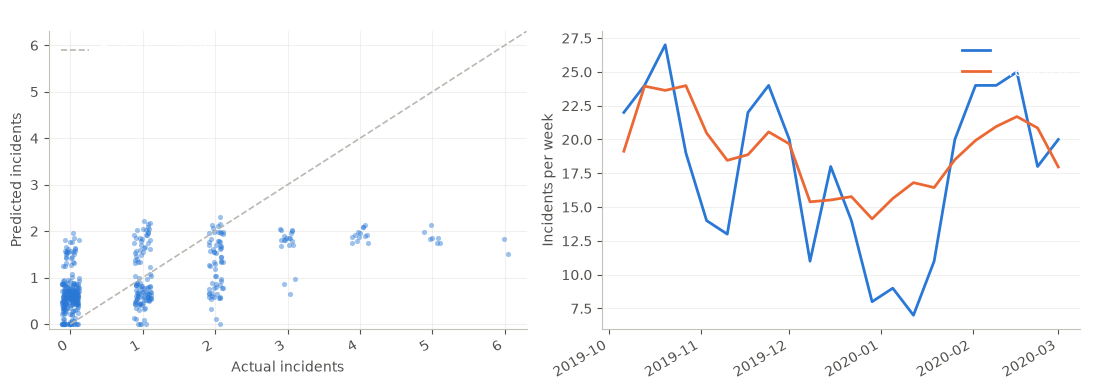

In [24]:
best_pred = test_pred[best_name]
rng = np.random.default_rng(RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# (a) actual vs predicted (jitter on the actual value because counts are whole numbers)
ax = axes[0]
ax.scatter(y_test + rng.uniform(-0.12, 0.12, len(y_test)), best_pred, s=14, color=BLUE, alpha=0.45, linewidths=0)
lim = max(y_test.max(), best_pred.max()) + 0.3
ax.plot([0, lim], [0, lim], color=GREY, ls='--', lw=1.2, label='Perfect prediction')
ax.set_xlim(-0.3, lim); ax.set_ylim(-0.1, lim)
ax.grid(axis='x')
ax.set_xlabel('Actual incidents'); ax.set_ylabel('Predicted incidents')
ax.set_title(f'Actual vs predicted ({best_name})'); ax.legend(loc='upper left')

# (b) weekly totals over the test period
ax = axes[1]
wk = pd.DataFrame({'Date': test['Date'], 'Actual': y_test.values, 'Predicted': best_pred}).set_index('Date').resample('W').sum()
ax.plot(wk.index, wk['Actual'], color=BLUE, lw=2, label='Actual')
ax.plot(wk.index, wk['Predicted'], color=ORANGE, lw=2, label='Predicted')
ax.set_title('Weekly incidents, all three major roads (test period)')
ax.set_ylabel('Incidents per week'); ax.legend(loc='upper right')
fig.autofmt_xdate()
plt.tight_layout(); plt.show()

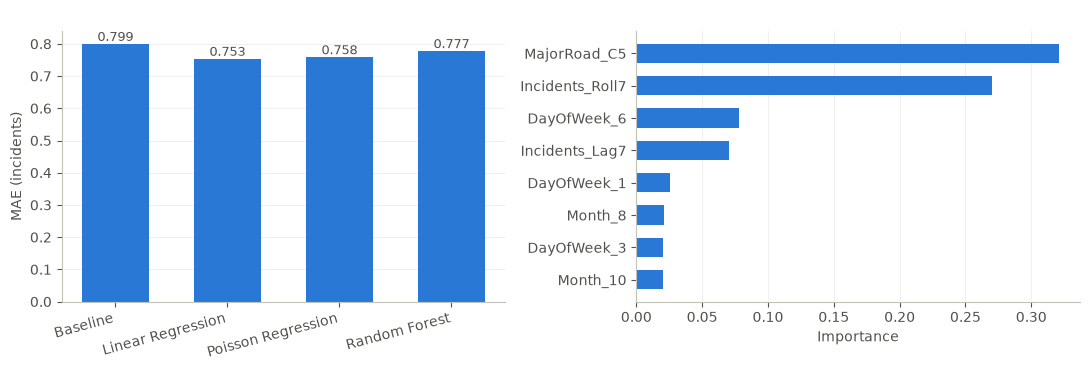

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# (c) test MAE by model
ax = axes[0]
mae = {n: mean_absolute_error(y_test, p) for n, p in test_pred.items()}
names = list(mae)
ax.bar(names, [mae[n] for n in names], color=BLUE, width=0.6)
for i, n in enumerate(names):
    ax.text(i, mae[n] + 0.01, f'{mae[n]:.3f}', ha='center', color=MUTED, fontsize=9)
ax.set_title('Test error by model (lower is better)'); ax.set_ylabel('MAE (incidents)')
ax.set_xticklabels(names, rotation=15, ha='right')

# (d) which features does the Random Forest rely on?
ax = axes[1]
rf = pipes['Random Forest']
fn = rf.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf.named_steps['model'].feature_importances_, index=fn).sort_values().tail(8)
imp.index = [i.replace('cat__', '').replace('num__', '') for i in imp.index]
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title('Random Forest: top feature importances'); ax.set_xlabel('Importance')
plt.tight_layout(); plt.show()

## 11. Performance Metrics

MAE (average miss in incidents), RMSE (penalizes big misses more) and R² (share of the variation explained) on the **test period**, compared with the baseline.

In [26]:
rows = []
for n, p in test_pred.items():
    rows.append({'Model': n,
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': mean_squared_error(y_test, p) ** 0.5,
                 'R2': r2_score(y_test, p)})
metrics = pd.DataFrame(rows).set_index('Model').round(3)
metrics['CV MAE (train)'] = cv_table['CV MAE (mean of 4 folds)']
display(metrics)

print(f'Best model by cross-validation: {best_name}')
print()
print('Test MAE by major road for', best_name)
by_c = pd.DataFrame({'MajorRoad': test['MajorRoad'], 'abs_err': np.abs(y_test.values - best_pred)}).groupby('MajorRoad')['abs_err'].mean().round(3)
print(by_c.to_string())

,MAE,RMSE,R2,CV MAE (train)
Model,,,,
Baseline,0.799,1.019,0.273,0.817
Linear Regression,0.753,0.976,0.333,0.765
Poisson Regression,0.758,0.962,0.353,0.779
Random Forest,0.777,1.001,0.299,0.788


Best model by cross-validation: Linear Regression

Test MAE by major road for Linear Regression
MajorRoad
C5         1.137
MARCOS     0.533
ORTIGAS    0.588


## 12. Conclusion

**DRAFT – the numbers below come from this notebook's run; the group should check them, add its own reading and rewrite in its own words.**

**Interpretation of the metrics.** On the test period (Oct 2019 – Feb 2020), all three models beat the baseline of each major road's average (MAE 0.799, R² 0.273):

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Baseline | 0.799 | 1.019 | 0.273 |
| Linear Regression | 0.753 | 0.976 | 0.333 |
| Poisson Regression | 0.758 | 0.962 | 0.353 |
| Random Forest | 0.777 | 1.001 | 0.299 |

Cross-validation on the training period chose Linear Regression (CV MAE 0.765, vs 0.817 for the baseline); Poisson Regression scored slightly better on RMSE and R² in the test period. The differences between the three models are small. On average the best model misses by about 0.75 incidents per road-day, roughly 6% lower than the baseline's error.

**What the model achieved.** It captures the general level of activity: it knows C5 is far busier than the other major roads, that weekends are quieter and that busy weeks tend to follow busy weeks (the weekly chart follows the actual trend). It explains about one third of the variation in daily counts (R² about 0.33).

**What it failed to do.** It never predicts more than about 2 incidents in a day, so it misses the busiest days (4–7 incidents). It also misses sudden drops, such as the very quiet weeks around the Christmas–New Year holidays, where actual counts fell to 7–9 per week and the model predicted 14–16. Most of the accuracy comes from the major road and the recent average, not from the calendar. The error is largest on C5 (MAE 1.14, against 0.53 for Marcos Highway and 0.59 for Ortigas) because C5 has the highest and most variable counts.

**Possible improvements.** Add Philippine holidays and school breaks, weather and rainfall, traffic volume or events, and finer location or time-of-day detail; use more than about 18 months of data; try models designed for counts with excess zeros; and compare more major roads.

**What the data reveals.** Reported incidents are concentrated on the C5 major road and on weekday mornings, so traffic managers could focus enforcers and tow trucks there first. Reported incidents on Ortigas and Marcos Highway are much rarer, and nearly absent on Sundays.

**Limitations.**
- The data holds only incidents that MMDA chose to tweet, not all incidents; major roads and times that MMDA monitors more closely look busier.
- Many rows have no `City`, including Marcos Highway rows, so the Marcos Highway counts are probably too low.
- Only about 18 months before the COVID-19 lockdown are used; March 2020 onward behaves differently and is excluded.
- Coordinates are location-level, and 74 incidents outside the three major roads were left out.
- The model explains only about one third of the variation, so it is a planning aid, not a precise forecast.

**Is the model ready for practical use?** Not yet. It should be treated as a starting point for planning and checked with MMDA or the Pasig traffic management office using more recent data before any real deployment decision depends on it.

**Data privacy, consent, fairness and responsible AI.** The data is public information posted by a government agency and contains no names, plate numbers or other personal details, only vehicle types and places. The source is cited. The results should not be used to blame drivers or neighborhoods, and the reporting bias above means a major road with few reported incidents is not necessarily safe. Any real use should keep a person responsible for deciding where to deploy resources.